### Libraries

In [1]:
import json
import numpy as np
import pandas as pd
from datetime import datetime
import folium
import math
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
import overpy
from geopy.distance import geodesic
from geopy import Point
import requests

### Load Line of Sight

In [2]:
json_path = "D:/OVGU/AMS project/GIT/AMS_ShipTraj/physics based model/sorted_centerline.json"

with open(json_path, 'r') as f:
    line_of_sight = json.load(f)

# Optional: preview a few points
print(f"Total points in line_of_sight: {len(line_of_sight)}")
print("First 3 points:", line_of_sight[:3])

Total points in line_of_sight: 156
First 3 points: [[48.966347, 8.233881499999999], [48.9668085, 8.235016000000002], [48.967312, 8.236104000000001]]


### Line of Sight reverse

In [3]:
line_of_sight_reverse = line_of_sight[::-1]

# Optional: Preview the reversed list
print("First 3 points of line_of_sight_reverse:", line_of_sight_reverse[:3])


First 3 points of line_of_sight_reverse: [[49.079716000000005, 8.3407615], [49.079031, 8.3398675], [49.0783725, 8.338960499999999]]


### Load the parameters

In [4]:
class ShipParameters:
    def __init__(self, initial_x, initial_y, heading_deg):
        # Physical constants
        self.rho_water = 1000  # kg/m³

        # Propeller parameters
        self.D = 3.0            # diameter [m]
        self.KT = 0.3           # thrust coefficient
        self.target_n_rpm = 180  # target rpm
        self.n_rpm = 0         # start from 0
        self.n = 0.0             # rev/s, will update during simulation

        # Rudder parameters
        self.AR = 15            # area [m²]
        self.CL = 0.8           # lift coefficient
        self.CD_rudder = 0.02   # drag coefficient
        self.delta_deg = 0    # rudder angle in degrees
        self.delta = np.radians(self.delta_deg)

        # Initial state
        self.u = 2.0            # surge velocity
        self.v = 0.0            # sway velocity
        self.r = 0.0            # yaw rate

        self.x = initial_x      # user input
        self.y = initial_y
        self.psi = np.radians(heading_deg)

        # Ship parameters
        self.mass = 6_500_000   # kg
        self.Iz = 4e8           # yaw moment of inertia
        self.xR = 60.0          # rudder distance from CG [m]

        # Drag
        self.S = 4000           # wetted surface [m²]
        self.CD = 0.002         # hull drag coeff

        self.tp = 0.15          # Thrust deduction factor
        self.w = 0.15           # Wake fraction


        # Simulation
        self.dt = 1           # time step [s]


### Calculate the forces

In [5]:
def calculate_J(params):
    denom = params.n * params.D
    if denom == 0:
        return 0.0  # Prevent divide by zero
    J = params.u * (1 - params.w) / denom
    return min(J, 5.0)  # clamp extreme cases


def KT_of_J(J):
    # Example quadratic fit
    a, b, c = 1.333, -0.8, -0.0667
    KT = a * J**2 + b * J + c
    if np.isnan(KT) or np.isinf(KT):
        return 0.0
    return max(0.1, min(KT, 0.4))  # clamp to realistic range


def calculate_propeller_force(params):
    J = calculate_J(params)
    KT = KT_of_J(J)
    TP = params.rho_water * params.n**2 * params.D**4 * KT
    XP = (1 - params.tp) * TP  # Surge contribution
    return XP

def calculate_drag_force(params):
    return 0.5 * params.rho_water * params.S * params.CD * params.u**2

def CL_of_delta(delta_rad):
    CL_slope = 6.0  # Lift slope (per radian)
    return CL_slope * delta_rad

def CD_of_delta(delta_rad):
    CD0 = 0.02
    k = 2.5
    return CD0 + k * delta_rad**2

def calculate_rudder_forces(params):
    params.delta = np.clip(params.delta, -np.radians(35), np.radians(35))

    UR = params.u
    delta = params.delta

    CL = CL_of_delta(delta)
    CD_rudder = CD_of_delta(delta)

    LR = 0.5 * params.rho_water * params.AR * UR**2 * CL
    DR = 0.5 * params.rho_water * params.AR * UR**2 * CD_rudder

    XR = -DR * np.cos(delta) + LR * np.sin(delta)
    YR = -DR * np.sin(delta) - LR * np.cos(delta)
    NR = YR * params.xR

    return XR, YR, NR

def calculate_wind_forces(params, vw, theta_w):
    """
    vw: wind speed (m/s)
    theta_w: wind direction FROM which wind is coming (degrees from North)
    """
    # Convert wind direction to radians and to direction TO which wind is going
    theta_w_rad = np.radians((theta_w + 180) % 360)

    # Project wind velocity onto ship axes
    uw = vw * np.cos(theta_w_rad - params.psi)
    vw_side = vw * np.sin(theta_w_rad - params.psi)

    # Coefficients (tune if needed)
    A_surge = 75  # frontal wind area
    A_sway = 225  # side wind area
    CD_wind = 0.6  # wind drag coefficient
    rho_air = 1.225  # kg/m³

    # Surge and sway wind forces (Xw and Yw)
    Xw = 0.5 * rho_air * CD_wind * A_surge * uw * abs(uw)
    Yw = 0.5 * rho_air * CD_wind * A_sway * vw_side * abs(vw_side)
    Nw = Yw * params.xR * 0.3  # Wind moment - simplified

    return Xw, Yw, Nw

def calculate_current_forces(params, Uc, theta_c):
    """
    Uc: current speed (m/s)
    theta_c: direction FROM which current is coming (° from North)
    """
    # Convert to direction TO which current is going
    theta_c_rad = np.radians((theta_c + 180) % 360)

    # Relative velocity of current in ship's frame
    uc_surge = Uc * np.cos(theta_c_rad - params.psi)
    uc_sway = Uc * np.sin(theta_c_rad - params.psi)

    # Parameters (tune if needed)
    A_surge_c = 25     # frontal underwater area
    A_sway_c = 75     # side underwater area
    CD_current = 0.6
    rho_water = params.rho_water

    # Current-induced forces (modeled similar to drag)
    Xc = 0.5 * rho_water * CD_current * A_surge_c * uc_surge * abs(uc_surge)
    Yc = 0.5 * rho_water * CD_current * A_sway_c * uc_sway * abs(uc_sway)
    Nc = Yc * params.xR * 0.3  # Simplified yaw moment

    return Xc, Yc, Nc


### Calculating the heading

In [6]:
def calculate_bearing(pointA, pointB):
    """
    Returns bearing from pointA to pointB (in degrees)
    """
    lat1, lon1 = map(math.radians, pointA)
    lat2, lon2 = map(math.radians, pointB)

    d_lon = lon2 - lon1

    x = math.sin(d_lon) * math.cos(lat2)
    y = math.cos(lat1)*math.sin(lat2) - math.sin(lat1)*math.cos(lat2)*math.cos(d_lon)

    bearing = math.atan2(x, y)
    return (math.degrees(bearing) + 360) % 360

def latlon_to_xy(lat, lon):
        R = 6371000
        x = math.radians(lon) * R * math.cos(math.radians(lat))
        y = math.radians(lat) * R
        return x, y


def get_wind_data(lat, lon, api_key):
    url = "http://api.openweathermap.org/data/2.5/weather"
    params = {
        'lat': lat,
        'lon': lon,
        'appid': api_key,
        'units': 'metric'
    }

    response = requests.get(url, params=params)
    data = response.json()

    if 'wind' not in data:
        raise ValueError("Wind data not found in API response.")

    wind_speed = data['wind'].get('speed', 0.0)
    wind_direction = data['wind'].get('deg', 0.0)
    return wind_speed, wind_direction

### Simulation

In [7]:
def simulate_motion(params, simulation_path, final_x, final_y):
    # Control parameters
    k = 5                      # Lower k → more aggressive rudder response
    max_rudder_deg = 35
    ramp_duration_sec = 60
    cte_gain = 0.6               # Increased to strengthen lateral correction
    cte_switch_threshold = 10  # Require small CTE before switching waypoint
    dt = params.dt
    

    # Tracking
    x_hist, y_hist = [params.x], [params.y]
    cte_hist = []
    ref_idx = 1
    current_ref = simulation_path[ref_idx]
    last_pos = (params.x, params.y)
    log_data = {}  # step-indexed dictionary


    # Wind data (optional, can be replaced with actual API call)
    api_key = "6c77c4bd0f7280bf206a277dc5407cab"
    vw, theta_w = get_wind_data(params.x, params.y, api_key)  # wind speed & direction in degrees


    

    
    
    final_point = [final_x, final_y]
    max_steps = 10000  # Safety cap
    step = 0

    while True:
        time_elapsed_sec = step * dt

        # Update wind data every 5 minutes
        if step % 300 == 0:  # Every 5 minutes (if dt=1s)
            vw, theta_w = get_wind_data(params.x, params.y, api_key)


        # Termination condition: within 5 meters of final point
        
        distance_to_goal = geodesic((params.x, params.y), final_point).meters
        if distance_to_goal < 10:
            print(f"Reached goal within 5m at step {step}, time {time_elapsed_sec:.1f}s")
            break

        if step >= max_steps:
            print("Max step limit reached.")
            break

        step += 1

        # Propeller ramp-up
        if time_elapsed_sec <= ramp_duration_sec:
            target_n_rpm = (params.target_n_rpm * time_elapsed_sec) / ramp_duration_sec
        else:
            target_n_rpm = params.target_n_rpm

        # Heading error
        current_pos = (params.x, params.y)
        bearing = calculate_bearing(current_pos, current_ref)
        required_heading = (90 - bearing) % 360
        current_heading = np.degrees(params.psi) % 360

        heading_error = required_heading - current_heading
        if heading_error > 180:
            heading_error -= 360
        elif heading_error < -180:
            heading_error += 360

        # Cross-track error
        if ref_idx + 1 < len(simulation_path):
            p1 = simulation_path[ref_idx]
            p2 = simulation_path[ref_idx + 1]
        else:
            p1 = simulation_path[ref_idx - 1]
            p2 = simulation_path[ref_idx]

        px, py = latlon_to_xy(params.x, params.y)
        x1, y1 = latlon_to_xy(p1[0], p1[1])
        x2, y2 = latlon_to_xy(p2[0], p2[1])

        dx, dy = x2 - x1, y2 - y1
        if dx == 0 and dy == 0:
            cte = 0
        else:
            u = ((px - x1) * dx + (py - y1) * dy) / (dx * dx + dy * dy)
            proj_x = x1 + u * dx
            proj_y = y1 + u * dy
            cte = ((px - proj_x)**2 + (py - proj_y)**2)**0.5
            cross = (x2 - x1)*(py - y1) - (y2 - y1)*(px - x1)
            cte *= np.sign(cross)

        cte_hist.append(cte)

        # Rudder control
        cte_effective = cte / max(1.0, params.u)  # scaled for speed
        rudder_angle = (-heading_error + cte_gain * cte_effective) / k

        rudder_angle = np.clip(rudder_angle, -max_rudder_deg, max_rudder_deg)
        dynamic_limit = np.clip(7 + (12 / max(params.u, 0.1)), 7, 25)
        rudder_angle = np.clip(rudder_angle, -dynamic_limit, dynamic_limit)

        # Thrust scaling
        thrust_factor = 0.5 if abs(rudder_angle) > 20 else 1.0
        params.n_rpm = target_n_rpm * thrust_factor
        params.n = params.n_rpm / 60.0
        params.delta = np.radians(rudder_angle)

        # Forces
        Fp = calculate_propeller_force(params)
        Fd = calculate_drag_force(params)
        XR, YR, NR = calculate_rudder_forces(params)
        Xw, Yw, Nw = calculate_wind_forces(params, vw, theta_w)
        Uc = 0.7       # Current speed [m/s]
        theta_c = 200  # Current FROM 200° → towards 20°

        Xc, Yc, Nc = calculate_current_forces(params, Uc, theta_c)


        # Motion update
        a_surge = (Fp - Fd + XR + Xw + Xc) / params.mass
        params.u = np.clip(params.u + a_surge * dt, 0.0, 12.0)
        """if time_elapsed_sec > 7100:
            params.u = np.clip(params.u + a_surge * dt, 0.0, 3.0)"""

        a_sway = (YR + Yw + Yc) / params.mass
        params.v += a_sway * dt

        r_dot = (NR + Nw + Nc) / params.Iz
        params.r += r_dot * dt
        params.r = np.clip(params.r, -0.4, 0.4)
        params.r *= 0.85
        params.psi += params.r * dt

        dx = (params.u * np.cos(params.psi) - params.v * np.sin(params.psi)) * dt
        dy = (params.u * np.sin(params.psi) + params.v * np.cos(params.psi)) * dt
        move_dist = math.hypot(dx, dy)
        move_bearing = math.degrees(math.atan2(dx, dy))
        new_point = geodesic(meters=move_dist).destination(Point(params.x, params.y), move_bearing)

        params.x = new_point.latitude
        params.y = new_point.longitude

        x_hist.append(params.x)
        y_hist.append(params.y)

        # Reference switching
        distance_to_ref = geodesic((params.x, params.y), current_ref).meters
        moved = geodesic(last_pos, (params.x, params.y)).meters
        last_pos = (params.x, params.y)

        if (
            distance_to_ref < 30
            and ref_idx + 1 < len(simulation_path)
        ):
            ref_idx += 1
            current_ref = simulation_path[ref_idx]
        
        #print(f"time: {time_elapsed_sec:.2f}s,  XP: {Fp:.2f}, Drag: {Fd:.2f},rudder forces: {XR , YR, NR}, wind forces: {Xw, Yw, Nw}, Speed: {params.u:.2f},asurge : {a_surge}, n : {params.n:.2f}, nrpm: {params.n_rpm:.2f}, rudder angle: {rudder_angle:.2f} deg, CTE: {cte:.2f}, Heading error: {heading_error:.2f} deg")

        """if time_elapsed_sec>11000:
            print(time_elapsed_sec, rudder_angle, cte, current_heading)"""
        if step % 1000 == 0:
            print(f"time: {time_elapsed_sec}")

        log_data[step] = {
            "timestamp": time_elapsed_sec,
            "latitude": params.x,
            "longitude": params.y,
            "x_velocity": params.u * np.cos(params.psi) - params.v * np.sin(params.psi),
            "y_velocity": params.u * np.sin(params.psi) + params.v * np.cos(params.psi),
            "heading": np.degrees(params.psi) % 360,
        }


    # Plot CTE
    plt.figure(figsize=(10, 3))
    plt.plot(cte_hist, label="Cross-Track Error (m)")
    plt.xlabel("Time step")
    plt.ylabel("CTE (m)")
    plt.grid()
    plt.legend()
    plt.title("Cross-Track Error Over Time")
    plt.tight_layout()
    plt.show()

    # Plot speed profile
    plt.figure(figsize=(10, 3))
    plt.plot([math.hypot(u, v) for u, v in zip(np.full_like(x_hist, params.u), np.zeros_like(x_hist))], label="Speed (m/s)")
    plt.xlabel("Time step")
    plt.ylabel("Speed (m/s)")
    plt.grid()
    plt.legend()
    plt.title("Ship Speed Over Time")
    plt.tight_layout()
    plt.show()

    return x_hist, y_hist, params, log_data

In [8]:
print(line_of_sight[0])

[48.966347, 8.233881499999999]


### Calculate the position

start
48.981312, 8.262617
48.91565412455895, 8.159050165027004
48.88834756378099, 8.135762089720629
end
48.99783768657771, 8.287111544559066
49.011177212038625, 8.296327230581149
49.01842616076212, 8.29925723451145
49.032260336757396, 8.302287434346168
49.059622253815526, 8.315441397005404

In [9]:
initial_x = line_of_sight[-1][0]
initial_y = line_of_sight[-1][1]
final_x = line_of_sight[0][0]
final_y = line_of_sight[0][1]



In [10]:
use_reverse = (final_x - initial_x) < 0
source_path = line_of_sight_reverse if use_reverse else line_of_sight


x_min = min(initial_x, final_x)
x_max = max(initial_x, final_x)


simulation_path = [pt for pt in source_path if x_min <= pt[0] <= x_max]

# Optional: Show number of points and first few
print(f"Direction: {'reverse' if use_reverse else 'forward'}")
print(f"Total points in simulation_path: {len(simulation_path)}")
print("First 3 points:", simulation_path[:3])

Direction: reverse
Total points in simulation_path: 156
First 3 points: [[49.079716000000005, 8.3407615], [49.079031, 8.3398675], [49.0783725, 8.338960499999999]]


[49.079716000000005, 8.3407615]
Initial heading: 229.47°
time: 999
time: 1999
time: 2999
time: 3999
time: 4999
time: 5999
time: 6999
time: 7999
time: 8999
time: 9999
Max step limit reached.


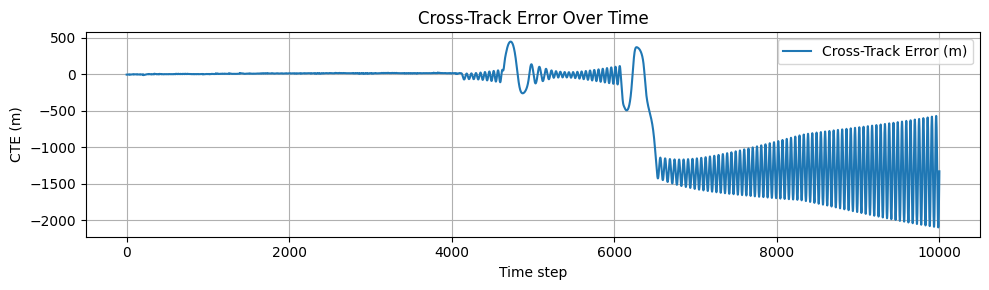

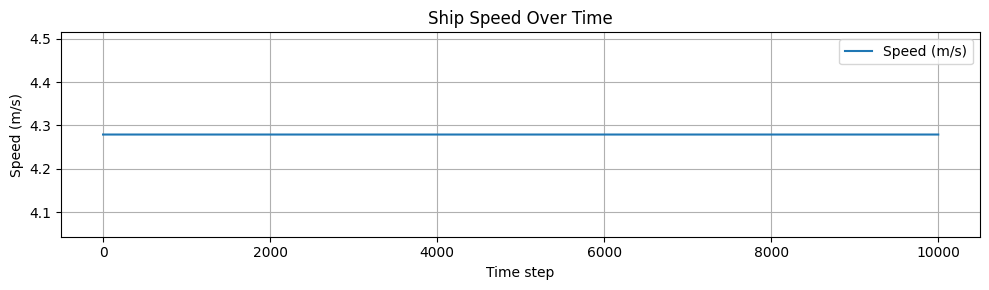

Final Heading: 217.61°
0.11944825063736318


In [11]:
# Reduce the reference path
reduced_path = simulation_path[::1]
print(reduced_path[0])  # Every alternate point

initial_heading_deg = (90 - calculate_bearing([initial_x,initial_y], reduced_path[1])) % 360
print(f"Initial heading: {initial_heading_deg:.2f}°")

# Initialize parameters
params = ShipParameters(initial_x, initial_y, initial_heading_deg)

# Run simulation
x_traj, y_traj, final_params, log_data = simulate_motion(params, reduced_path, final_x, final_y)



# Print final result
"""print(f"Final Position: ({final_params.x:.6f}, {final_params.y:.6f})")
print(f"Final Speed: {final_params.u:.2f} m/s")"""
print(f"Final Heading: {np.degrees(final_params.psi)%360:.2f}°")
print(final_params.r)

### Ploting the position using Folium

In [12]:
# 1. Define start location for map center
start_location = [x_traj[0], y_traj[0]]
m = folium.Map(location=start_location, zoom_start=14)

# 2. Create trajectory path (ship motion path)
trajectory = list(zip(x_traj, y_traj))

# 3. Add simulated trajectory to map
folium.PolyLine(
    locations=trajectory,
    color="blue",
    weight=3,
    opacity=0.7,
    tooltip="Simulated Ship Path"
).add_to(m)

# 4. Add start and end markers for trajectory
folium.Marker(location=trajectory[0], popup="Start", icon=folium.Icon(color='green')).add_to(m)
folium.Marker(location=trajectory[-1], popup="End", icon=folium.Icon(color='red')).add_to(m)

# 5. Add reference path (simulation_path)
folium.PolyLine(
    locations=simulation_path,
    color="purple",
    weight=2,
    opacity=0.7,
    tooltip="Reference Path (simulation_path)"
).add_to(m)

# 6. Optionally: add marker at each reference point
for idx, point in enumerate(simulation_path):
    folium.CircleMarker(
        location=point,
        radius=2,
        color="purple",
        fill=True,
        fill_opacity=0.7,
        popup=f"Ref {idx}"
    ).add_to(m)

# 7. Display the map
m

In [13]:
for step in sorted(log_data):
    if step % 500 == 0:
        print(f"Step {step}:", log_data[step])

Step 500: {'timestamp': 499, 'latitude': 49.070953491597784, 'longitude': 8.32674026799094, 'x_velocity': -2.267821823350448, 'y_velocity': -2.6708962631136814, 'heading': 228.15603746464862}
Step 1000: {'timestamp': 999, 'latitude': 49.05663007858422, 'longitude': 8.314299702110429, 'x_velocity': -1.910601265926267, 'y_velocity': -3.2635268381796765, 'heading': 234.677283049113}
Step 1500: {'timestamp': 1499, 'latitude': 49.0409991789947, 'longitude': 8.303936356080607, 'x_velocity': -0.9326564111306407, 'y_velocity': -3.734082346400785, 'heading': 246.87725084410724}
Step 2000: {'timestamp': 1999, 'latitude': 49.023632059516466, 'longitude': 8.30105263460297, 'x_velocity': -0.2798588524377673, 'y_velocity': -3.9426872122950765, 'heading': 251.42515686502784}
Step 2500: {'timestamp': 2499, 'latitude': 49.00668003645657, 'longitude': 8.293700225008498, 'x_velocity': -2.0335672328709316, 'y_velocity': -3.397359325857289, 'heading': 222.5118754165285}
Step 3000: {'timestamp': 2999, 'lati